<a href="https://colab.research.google.com/github/JacobKhay/L02-hedonic-pricing/blob/main/L2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nithya Gopal, Jacob Khaykin, Heidi Williams

**Date:** 11/09/2026

### **Questions 1 & 2**

In [1]:
!git clone https://github.com/JacobKhay/L02-hedonic-pricing.git

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

houses = pd.read_csv("L02-hedonic-pricing/data/pierce_county_house_sales.csv")
print("Original shape:", houses.shape)
display(houses.dtypes)
display(houses.isna().sum())
print("Duplicate rows:", houses.duplicated().sum())

houses = houses.drop_duplicates().copy()
houses["sale_date"] = pd.to_datetime(houses["sale_date"])
category_columns = houses.select_dtypes(include=["object", "string"]).columns
houses[category_columns] = houses[category_columns].fillna("Unknown")
print("Cleaned shape:", houses.shape)
print("Remaining missing values:", houses.isna().sum().sum())

Cloning into 'L02-hedonic-pricing'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 24 (delta 8), reused 1 (delta 1), pack-reused 9 (from 1)
Receiving objects: 100% (24/24), 451.01 KiB | 6.94 MiB/s, done.
Resolving deltas: 100% (8/8), done.
Original shape: (16814, 19)


,0
sale_date,object
sale_price,int64
house_square_feet,int64
attic_finished_square_feet,int64
basement_square_feet,int64
attached_garage_square_feet,int64
detached_garage_square_feet,int64
fireplaces,int64
hvac_description,object
exterior,object


,0
sale_date,0
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
hvac_description,7
exterior,1


Duplicate rows: 46
Cleaned shape: (16768, 19)
Remaining missing values: 0


,sale_price,house_square_feet,bedrooms,bathrooms
count,1.676800e+04,16768.000000,16768.000000,16768.000000
mean,4.612053e+05,1879.174082,3.276419,2.316078
std,2.361158e+05,760.438267,0.891160,0.828058
min,2.000000e+03,1.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,3.000000,2.000000
50%,4.167250e+05,1774.000000,3.000000,2.000000
75%,5.238815e+05,2351.250000,4.000000,3.000000
max,6.130000e+06,9510.000000,25.000000,8.000000


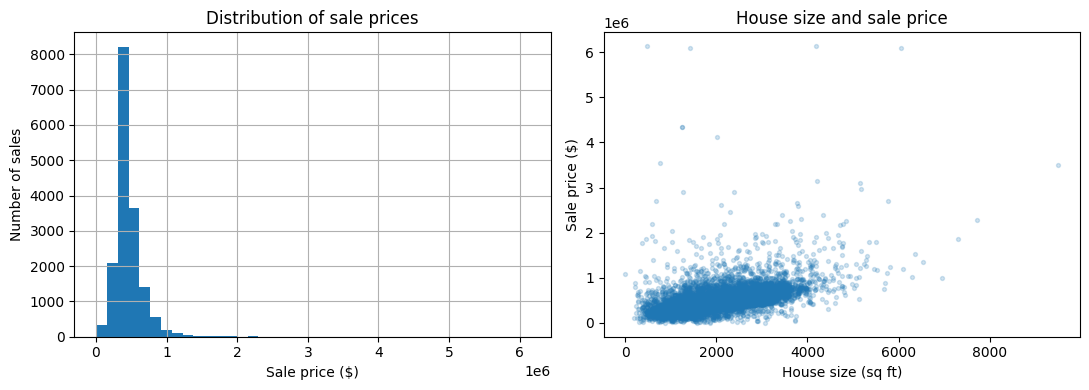

In [2]:
display(houses[["sale_price", "house_square_feet", "bedrooms", "bathrooms"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
houses["sale_price"].hist(bins=40, ax=axes[0])
axes[0].set(title="Distribution of sale prices", xlabel="Sale price ($)", ylabel="Number of sales")
axes[1].scatter(houses["house_square_feet"], houses["sale_price"], alpha=0.2, s=8)
axes[1].set(title="House size and sale price", xlabel="House size (sq ft)", ylabel="Sale price ($)")
plt.tight_layout()
plt.show()

As seen by the distribution above, sale prices are skewed to the right. Furthermore, larger houses generally sell for more.

### **Question 3**

In [3]:
X = pd.get_dummies(
    houses.drop(columns=["sale_price", "sale_date"]),
    columns=category_columns,
    drop_first=True,
    dtype=int,
)
y = houses["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=112
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Features:", X_train.shape[1])

Training rows: 13414
Test rows: 3354
Features: 59


### **Question 4**

In [15]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Define feature sets
models = {
    "Model 1 (Sq Ft)": ['house_square_feet'],
    "Model 2 (Sq Ft, Bed, Bath)": ['house_square_feet', 'bedrooms', 'bathrooms'],
    "Model 3 (All features)": X_train.columns.tolist()
}

# Train and evaluate models
for name, features in models.items():
    lr = LinearRegression().fit(X_train[features], y_train)

    tr_rmse = np.sqrt(mean_squared_error(y_train, lr.predict(X_train[features])))
    te_rmse = np.sqrt(mean_squared_error(y_test, lr.predict(X_test[features])))
    tr_r2 = r2_score(y_train, lr.predict(X_train[features]))
    te_r2 = r2_score(y_test, lr.predict(X_test[features]))

    print(f"{name}:\n  Train -> RMSE: ${tr_rmse:,.2f}, R2: {tr_r2:.4f}\n  Test  -> RMSE: ${te_rmse:,.2f}, R2: {te_r2:.4f}\n")

Model 1 (Sq Ft):
  Train -> RMSE: $199,176.34, R2: 0.2818
  Test  -> RMSE: $207,327.60, R2: 0.2560

Model 2 (Sq Ft, Bed, Bath):
  Train -> RMSE: $196,309.45, R2: 0.3023
  Test  -> RMSE: $204,599.94, R2: 0.2755

Model 3 (All features):
  Train -> RMSE: $157,821.58, R2: 0.5491
  Test  -> RMSE: $164,837.37, R2: 0.5297



#### **Explanation**

The first model, with one feature (house_square_feet), captures only size and yields an $R^2$ value of 0.2560 and a high RMSE of $207,327.60

The second model, with three features (house_square_feet, bedrooms, and bathrooms), marginally improves performance after adding two features, with a slightly higher $R^2$ value of 0.2755

The third model, with all features, dramatically improves performance by incorporating all available characteristics, and yields an $R^2$ value of 0.5297 and an RMSE of $164,837.37

Model 3 performs the best out of the simple models, indicating that a home's overall value is determined by a combination of many structural and neighborhood properties rather than size alone.


### **Question 5**

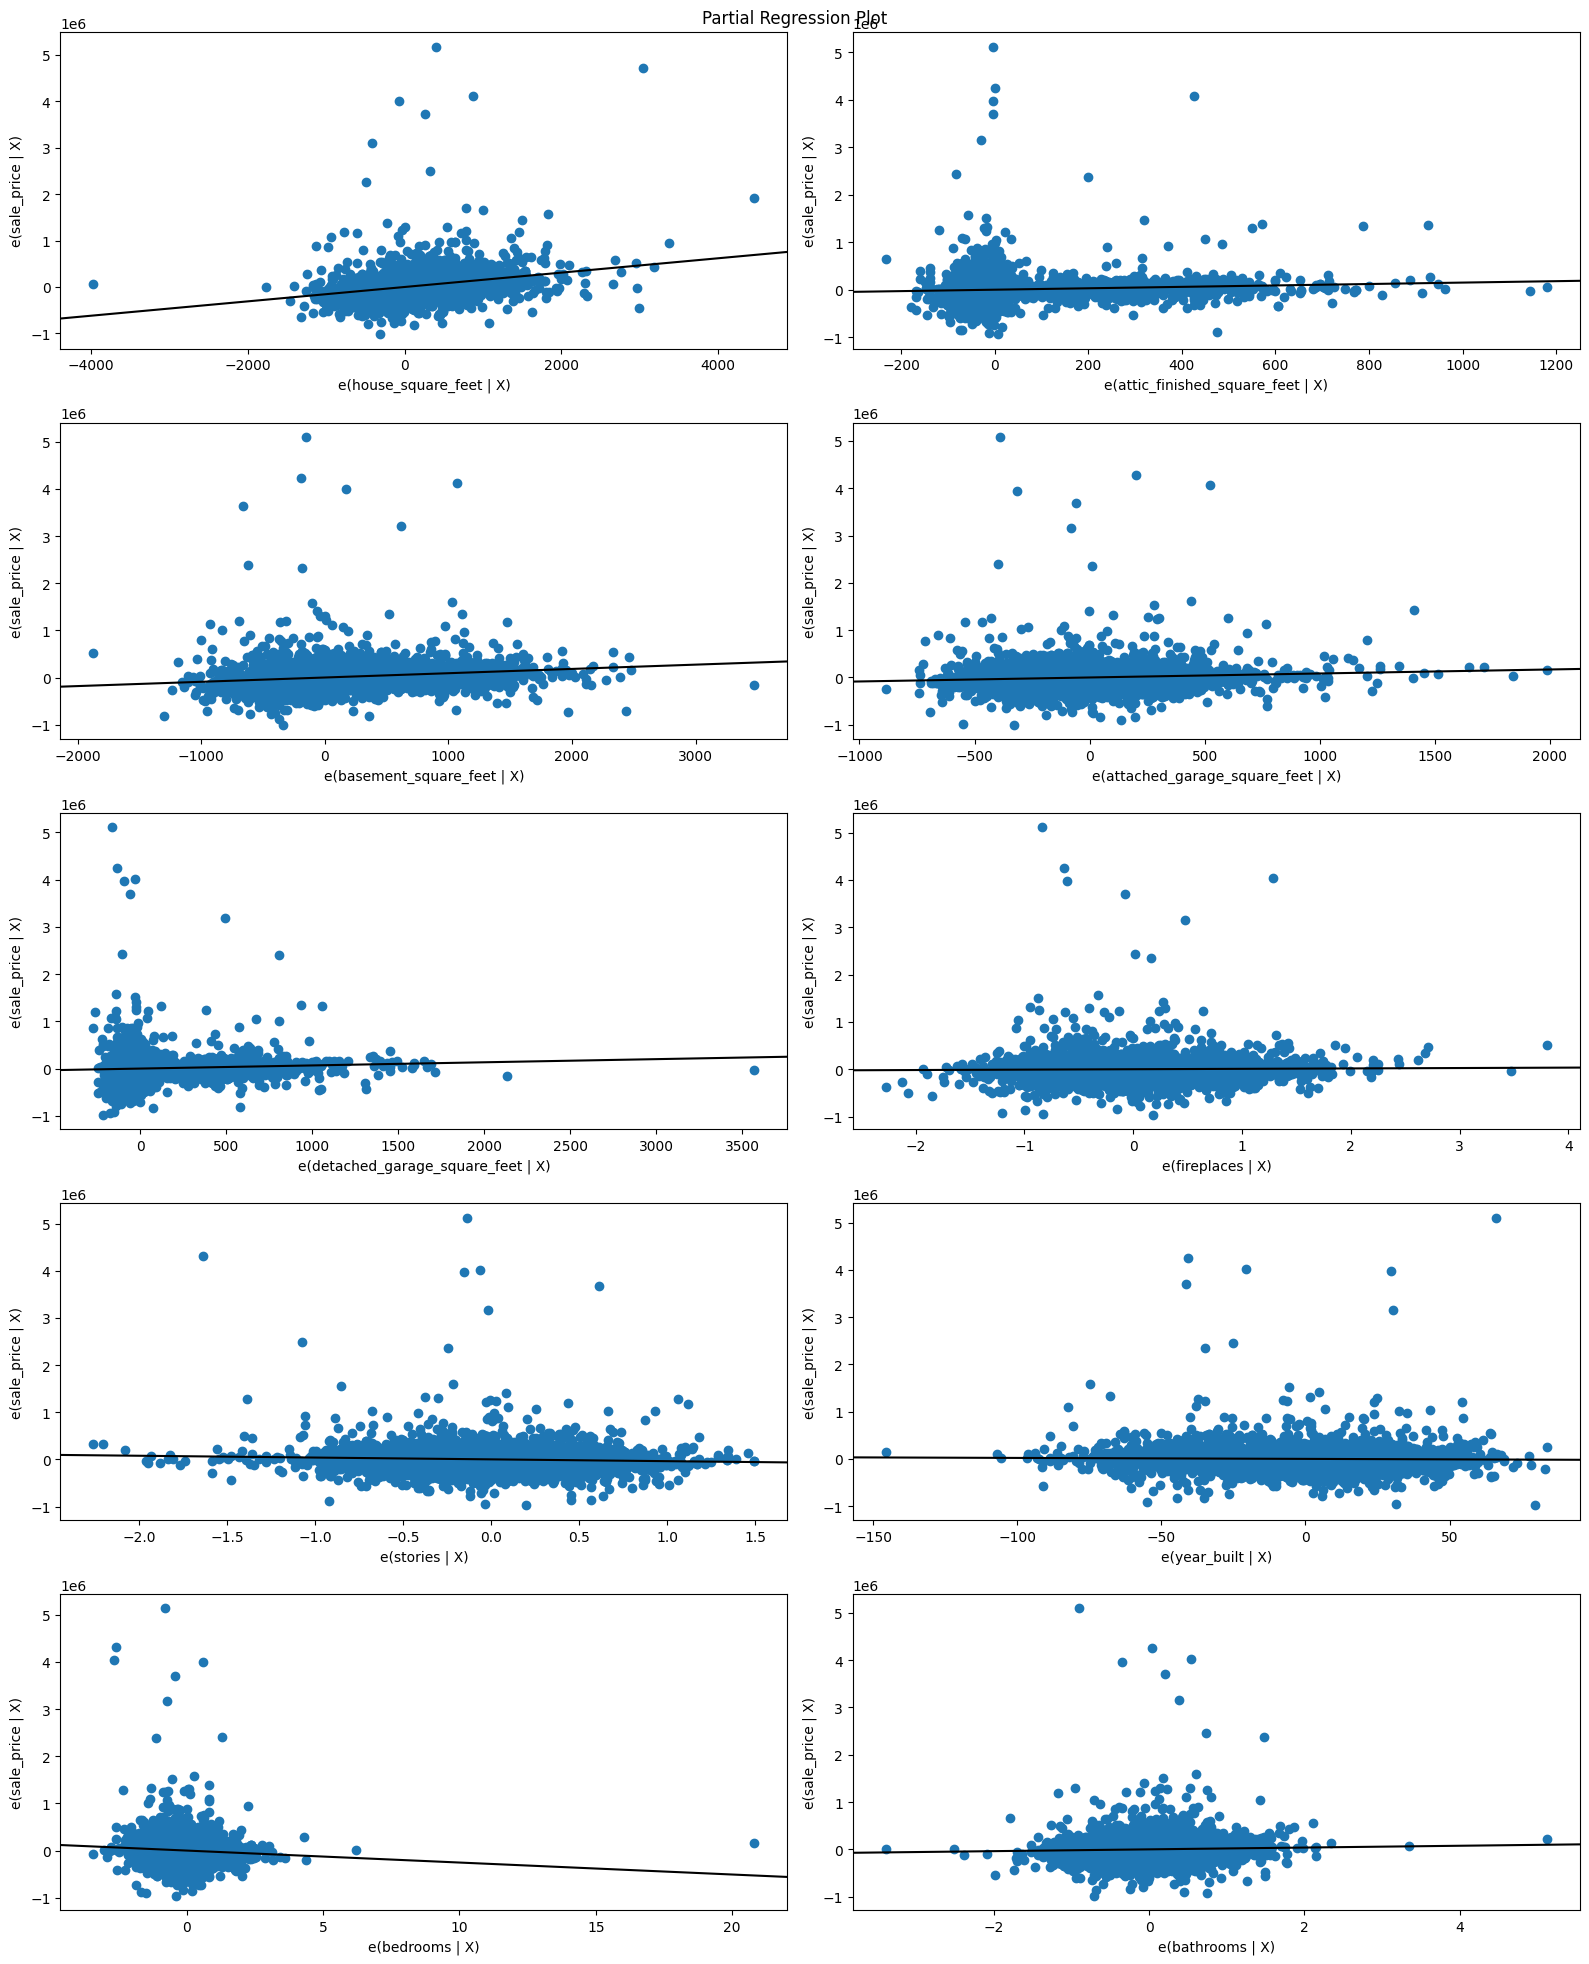

In [11]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Fit OLS and plot partial regressions
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

numeric_features = houses.select_dtypes(include="number").columns.drop("sale_price")

fig = plt.figure(figsize=(16, 20))
sm.graphics.plot_partregress_grid(model_sm, exog_idx=numeric_features.tolist(), fig=fig)
plt.tight_layout()
plt.show()

#### **Explanation**
The partial correlation plots show a clear, positive, and linear trend between house square footage and sale price (even after controlling for other variables). However, structural features like bedrooms, bathrooms, and stories show more scattered or step-wise relationships. This indicates that size has a strong continuous effect, whereas adding raw counts of bedrooms or bathrooms might benefit from non-linear modeling or categorical treatment.

### **Question 6**

In [6]:
# Log-transform target
y_train_log, y_test_log = np.log(y_train), np.log(y_test)

# Create non-linear and interaction features
X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

for df in [X_train_complex, X_test_complex]:
    df['sq_ft_squared'] = df['house_square_feet'] ** 2
    df['bed_bath_interaction'] = df['bedrooms'] * df['bathrooms']

# Fit model and evaluate
lr_complex = LinearRegression().fit(X_train_complex, y_train_log)

y_tr_pred = np.exp(lr_complex.predict(X_train_complex))
y_te_pred = np.exp(lr_complex.predict(X_test_complex))

print(f"Complex Model (with Log target & interactions):\n"
      f"  Train - RMSE: ${np.sqrt(mean_squared_error(y_train, y_tr_pred)):,.2f}, R2: {r2_score(y_train, y_tr_pred):.4f}\n"
      f"  Test  - RMSE: ${np.sqrt(mean_squared_error(y_test, y_te_pred)):,.2f}, R2: {r2_score(y_test, y_te_pred):.4f}")

Complex Model (with Log target & interactions):
  Train - RMSE: $154,573.10, R2: 0.5674
  Test  - RMSE: $167,451.91, R2: 0.5147


#### **Explanation**

In this more complex model, we transitioned to a log-transformed sale price and added non-linear terms (squared square feet and a bedroom-bathroom interaction) helped improved the fit on the training data ($R^2$ = 0.5674 compared to Model 3's 0.5491).

Additionally, on the test set, the complex model's $R^2$ dropped to 0.5174 (with an RMSE of $167,451.91)

which is slightly worse than Model 3's test $R^2$ of 0.5297. This demonstrates that adding custom interactions and polynomial features can easily introduce overfitting, where the model performs better on training data but not as well to unseen test data.

###**Question 7**

Looking at our results, we think Models 1 and 2 were underfitting because they did not account for enough factors that influence house prices. Model 1 only used square footage and had a test R-squared of 0.2560, while Model 2 slightly improved to 0.2755 by including bedrooms and bathrooms. Model 3 performed much better, with a test R-squared of 0.5297, showing that adding more relevant features helped improve our predictions. However, when we made the model more complex in Model 4, we started to see some overfitting. Even though the training R² increased from 0.5491 to 0.5674, the test R-squared actually dropped from 0.5297 to 0.5147. I think this shows that making a model more complicated does not necessarily make it better at predicting new data. Overall, Model 3 was our best choice because it performed the best on the test data without adding unnecessary complexity. From this, we learned that model selection is about finding a balance between having enough features to avoid underfitting and not making the model so complex that it starts overfitting.

### **Question 8**

In [14]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

#Scale the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_complex)
X_test_scaled = scaler.transform(X_test_complex)

#Train Lasso
lasso = Lasso(alpha=0.001, max_iter=20000)
lasso.fit(X_train_scaled, y_train_log)

print("Selected features are-", X_train_complex.columns[lasso.coef_ != 0].tolist())

#Evaluat model
for name, X_data, y_data in [("Train", X_train_scaled, y_train), ("Test", X_test_scaled, y_test)]:
    pred = np.exp(lasso.predict(X_data))
    rmse = np.sqrt(mean_squared_error(y_data, pred))
    r2 = r2_score(y_data, pred)
    print("r2=", r2, "rmse=", rmse)


Selected features are- ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms', 'hvac_description_Electric Baseboard', 'hvac_description_Floor/Wall Furnace', 'hvac_description_Heat Pump', 'hvac_description_Hot Water Baseboard', 'hvac_description_No Heat', 'hvac_description_Unknown', 'hvac_description_Warm and Cool Air Zone', 'exterior_Cedar Finished Cabin', 'exterior_Cedar Unfinished Cabin', 'exterior_Finished Cottage', 'exterior_Frame Rustic Log', 'exterior_Frame Stucco', 'exterior_Frame Vinyl', 'exterior_Log', 'exterior_Masonry Common Brick', 'exterior_Masonry Concrete Block', 'exterior_Pine A-Frame', 'exterior_Pine Finished Cabin', 'exterior_Pine Unfinished Cabin', 'exterior_Unfinished Cottage', 'exterior_Unknown', 'interior_Paneling', 'interior_Unknown', 'roof_cover_Concrete Tile', 'roof_cover_Preformed Metal', 'roof_cover_Unknown', 'roof_

Lasso selected 54 features: house_square_feet, attic_finished_square_feet, basement_square_feet, attached_garage_square_feet, detached_garage_square_feet, fireplaces, stories, year_built, bedrooms, bathrooms, hvac_description_Electric Baseboard, hvac_description_Floor/Wall Furnace, hvac_description_Heat Pump, hvac_description_Hot Water Baseboard, hvac_description_No Heat, hvac_description_Unknown, hvac_description_Warm and Cool Air Zone, exterior_Cedar Finished Cabin, exterior_Cedar Unfinished Cabin, exterior_Finished Cottage, exterior_Frame Rustic Log, exterior_Frame Stucco, exterior_Frame Vinyl, exterior_Log, exterior_Masonry Common Brick, exterior_Masonry Concrete Block, exterior_Pine A-Frame, exterior_Pine Finished Cabin, exterior_Pine Unfinished Cabin, exterior_Unfinished Cottage, exterior_Unknown, interior_Paneling, interior_Unknown, roof_cover_Concrete Tile, roof_cover_Preformed Metal, roof_cover_Unknown, roof_cover_Wood Shake, waterfront_type_WF Lake, waterfront_type_WF River, waterfront_type_WF Salt, view_quality_View Avg, view_quality_View Avg +, view_quality_View Good, view_quality_View Good +, view_quality_View Lim, view_quality_View Lim +, view_quality_View Lim -, view_quality_View V-Good, utility_sewer_SEWER/SEPTIC AVAIL, utility_sewer_SEWER/SEPTIC INSTALLED, utility_sewer_SEWER/SEPTIC NO, utility_sewer_SEWER/SEPTIC NO PERC, sq_ft_squared, and bed_bath_interaction.



The training RMSE was 155,601.26 dollars with an R squared of 0.5617, while the test RMSE was 167,564.94 dollars with an R squared of 0.5140.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 6d147194e01dc5ef9919e1487f894e4b887fefea
- **AI tool and model used:** ChatGPT GPT-6

### *Prompts used

1. look over this notebook and tell me if there are places where we did not follow instructions or may lose points; objective only no subjective ideas
2. give a bulleted list of changes to make

### *AI-proposed changes


1. Question 4: Escape the dollar signs before house prices using \$ so Markdown doesn't interpret them as mathematical notation.
2. Question 6: Change the test R squared value from 0.5174 to 0.5147 in your written explanation.
3. Question 6: Escape the dollar sign before the RMSE value to prevent Markdown formatting problems.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | This was a typo, so this suggestion was used. This was verified by rereading the outputs of our code. |
| 2 | Accept | This is a style choice that we thought would make formatting easier, verified with a simple google search on how to escape the dollar sign and why it is done. |
| 3 | Accept | This is a style choice that we thought would make formatting easier, verified with a simple google search on how to escape the dollar sign and why it is done. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### **Questions 1 & 2**

In [16]:
!git clone https://github.com/JacobKhay/L02-hedonic-pricing.git

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

houses = pd.read_csv("L02-hedonic-pricing/data/pierce_county_house_sales.csv")
print("Original shape:", houses.shape)
display(houses.dtypes)
display(houses.isna().sum())
print("Duplicate rows:", houses.duplicated().sum())

houses = houses.drop_duplicates().copy()
houses["sale_date"] = pd.to_datetime(houses["sale_date"])
category_columns = houses.select_dtypes(include=["object", "string"]).columns
houses[category_columns] = houses[category_columns].fillna("Unknown")
print("Cleaned shape:", houses.shape)
print("Remaining missing values:", houses.isna().sum().sum())

fatal: destination path 'L02-hedonic-pricing' already exists and is not an empty directory.
Original shape: (16814, 19)


,0
sale_date,object
sale_price,int64
house_square_feet,int64
attic_finished_square_feet,int64
basement_square_feet,int64
attached_garage_square_feet,int64
detached_garage_square_feet,int64
fireplaces,int64
hvac_description,object
exterior,object


,0
sale_date,0
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
hvac_description,7
exterior,1


Duplicate rows: 46
Cleaned shape: (16768, 19)
Remaining missing values: 0


,sale_price,house_square_feet,bedrooms,bathrooms
count,1.676800e+04,16768.000000,16768.000000,16768.000000
mean,4.612053e+05,1879.174082,3.276419,2.316078
std,2.361158e+05,760.438267,0.891160,0.828058
min,2.000000e+03,1.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,3.000000,2.000000
50%,4.167250e+05,1774.000000,3.000000,2.000000
75%,5.238815e+05,2351.250000,4.000000,3.000000
max,6.130000e+06,9510.000000,25.000000,8.000000


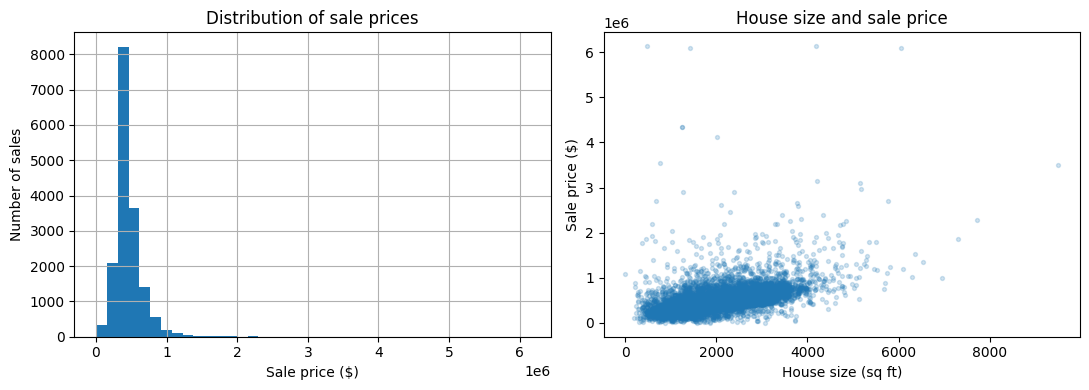

In [17]:
display(houses[["sale_price", "house_square_feet", "bedrooms", "bathrooms"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
houses["sale_price"].hist(bins=40, ax=axes[0])
axes[0].set(title="Distribution of sale prices", xlabel="Sale price ($)", ylabel="Number of sales")
axes[1].scatter(houses["house_square_feet"], houses["sale_price"], alpha=0.2, s=8)
axes[1].set(title="House size and sale price", xlabel="House size (sq ft)", ylabel="Sale price ($)")
plt.tight_layout()
plt.show()

As seen by the distribution above, sale prices are skewed to the right. Furthermore, larger houses generally sell for more.

### Question 3

In [18]:
X = pd.get_dummies(
    houses.drop(columns=["sale_price", "sale_date"]),
    columns=category_columns,
    drop_first=True,
    dtype=int,
)
y = houses["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=112
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Features:", X_train.shape[1])

Training rows: 13414
Test rows: 3354
Features: 59


### Question 4

In [19]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Define feature sets
models = {
    "Model 1 (Sq Ft)": ['house_square_feet'],
    "Model 2 (Sq Ft, Bed, Bath)": ['house_square_feet', 'bedrooms', 'bathrooms'],
    "Model 3 (All features)": X_train.columns.tolist()
}

# Train and evaluate models
for name, features in models.items():
    lr = LinearRegression().fit(X_train[features], y_train)

    tr_rmse = np.sqrt(mean_squared_error(y_train, lr.predict(X_train[features])))
    te_rmse = np.sqrt(mean_squared_error(y_test, lr.predict(X_test[features])))
    tr_r2 = r2_score(y_train, lr.predict(X_train[features]))
    te_r2 = r2_score(y_test, lr.predict(X_test[features]))

    print(f"{name}:\n  Train -> RMSE: ${tr_rmse:,.2f}, R2: {tr_r2:.4f}\n  Test  -> RMSE: ${te_rmse:,.2f}, R2: {te_r2:.4f}\n")

Model 1 (Sq Ft):
  Train -> RMSE: $199,176.34, R2: 0.2818
  Test  -> RMSE: $207,327.60, R2: 0.2560

Model 2 (Sq Ft, Bed, Bath):
  Train -> RMSE: $196,309.45, R2: 0.3023
  Test  -> RMSE: $204,599.94, R2: 0.2755

Model 3 (All features):
  Train -> RMSE: $157,821.58, R2: 0.5491
  Test  -> RMSE: $164,837.37, R2: 0.5297



#### **Explanation**

The first model, with one feature (house_square_feet), captures only size and yields an $R^2$ value of 0.2560 and a high RMSE of \$207,327.60

The second model, with three features (house_square_feet, bedrooms, and bathrooms), marginally improves performance after adding two features, with a slightly higher $R^2$ value of 0.2755

The third model, with all features, dramatically improves performance by incorporating all available characteristics, and yields an $R^2$ value of 0.5297 and an RMSE of \$164,837.37

Model 3 performs the best out of the simple models, indicating that a home's overall value is determined by a combination of many structural and neighborhood properties rather than size alone.

### Question 5

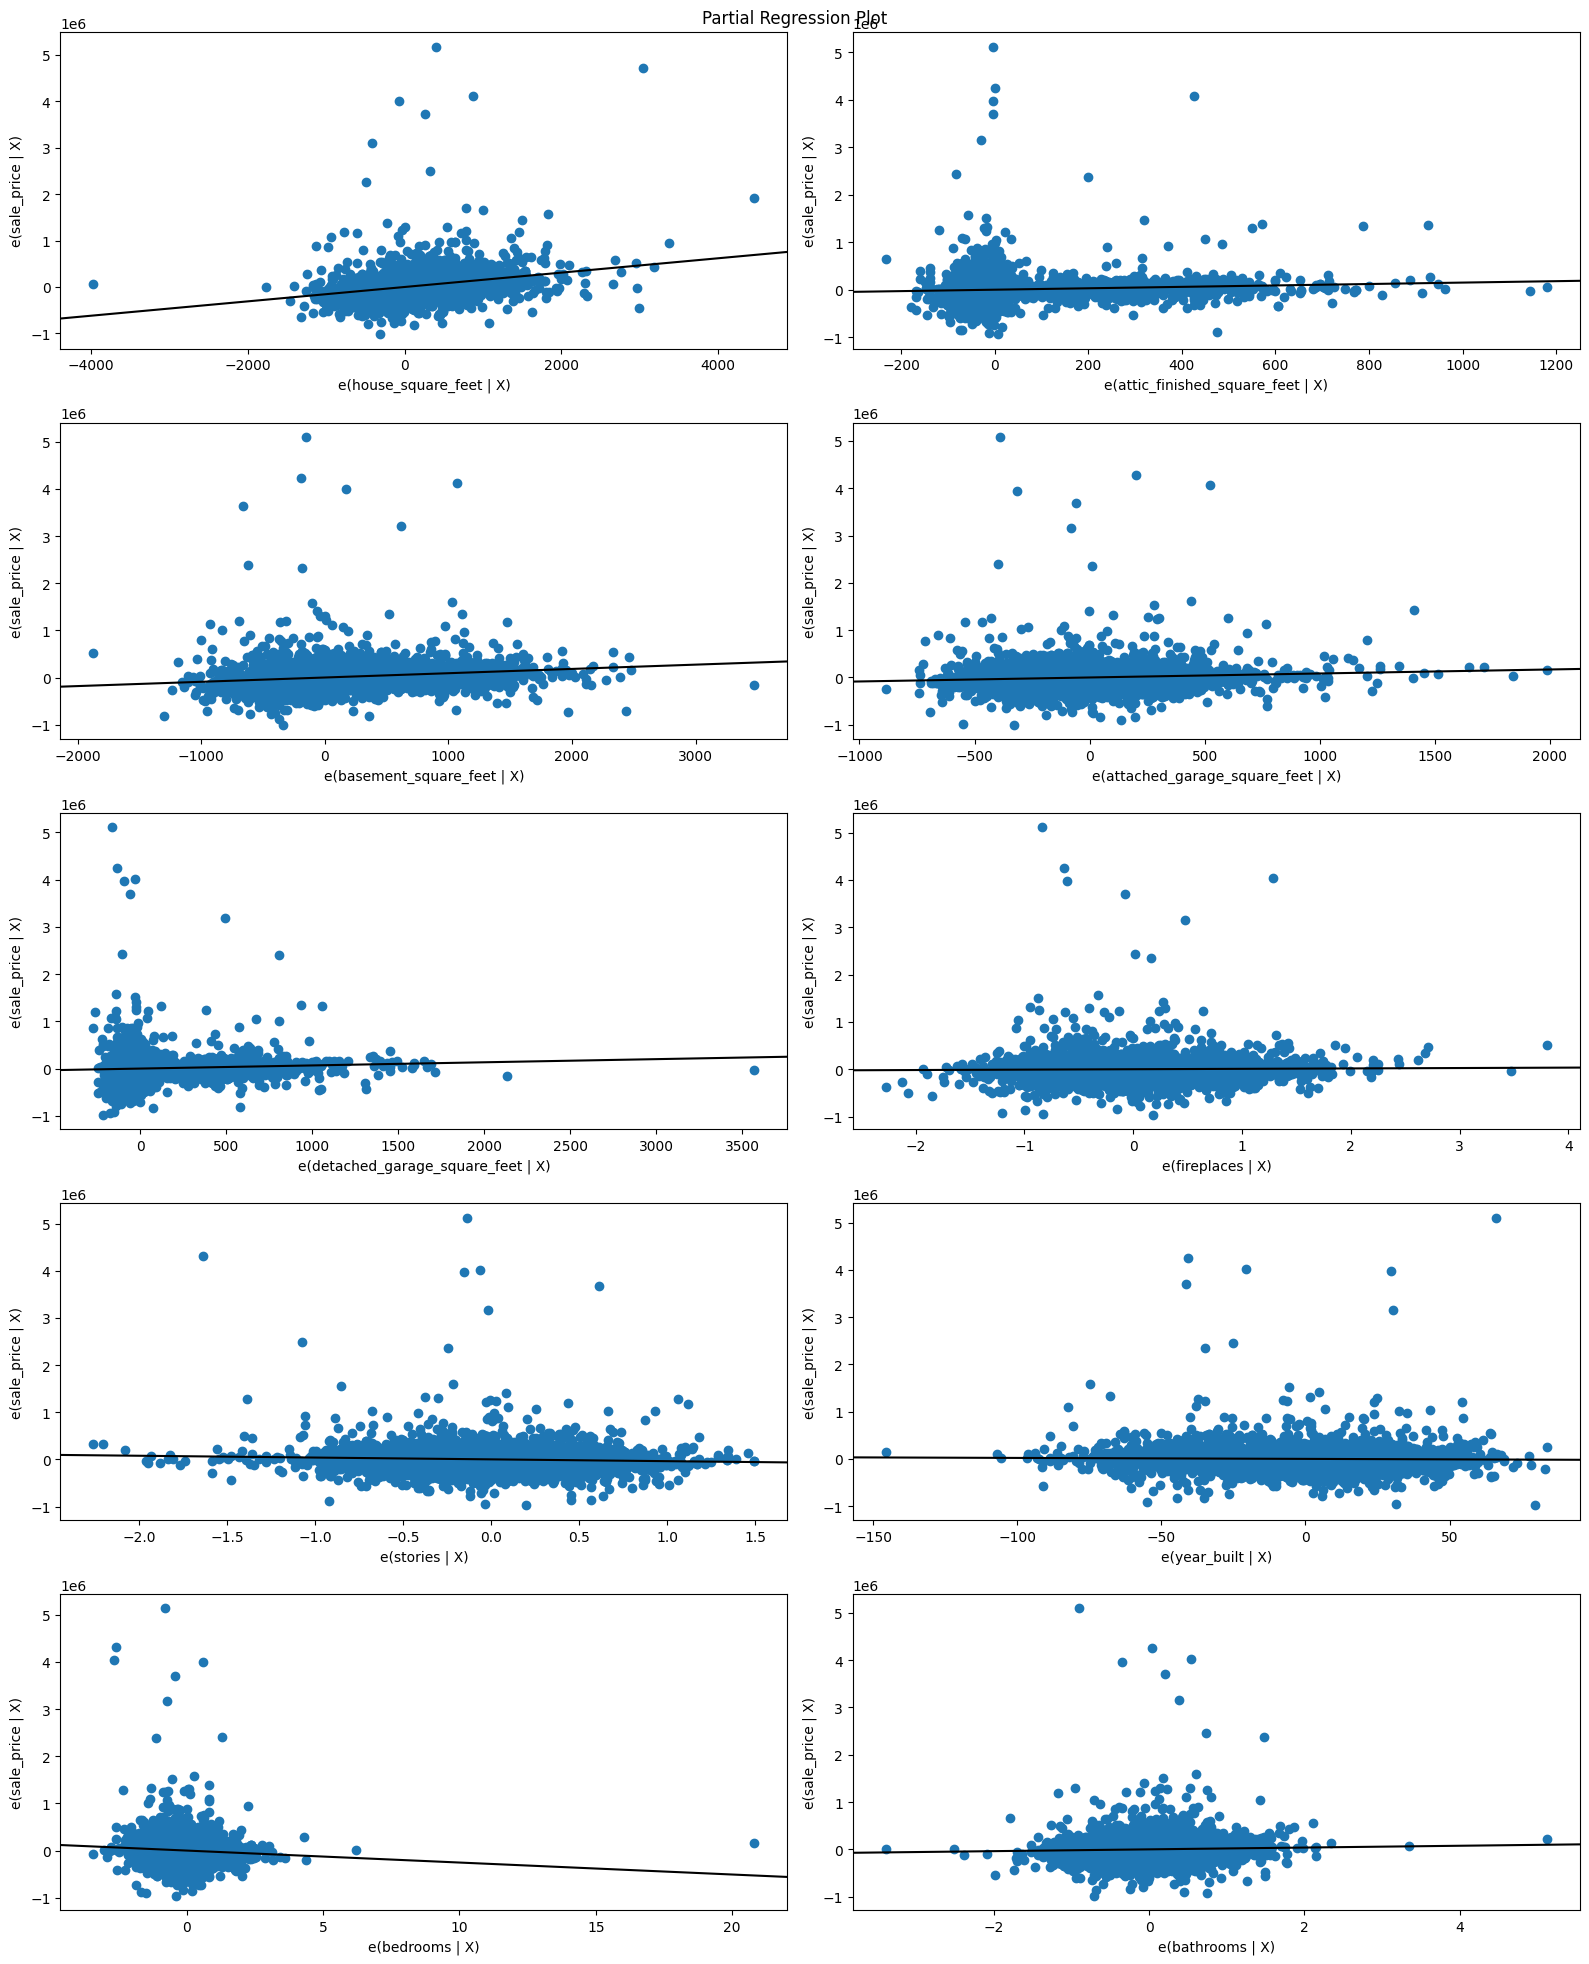

In [20]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Fit OLS and plot partial regressions
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

numeric_features = houses.select_dtypes(include="number").columns.drop("sale_price")

fig = plt.figure(figsize=(16, 20))
sm.graphics.plot_partregress_grid(model_sm, exog_idx=numeric_features.tolist(), fig=fig)
plt.tight_layout()
plt.show()

#### **Explanation**
The partial correlation plots show a clear, positive, and linear trend between house square footage and sale price (even after controlling for other variables). However, structural features like bedrooms, bathrooms, and stories show more scattered or step-wise relationships. This indicates that size has a strong continuous effect, whereas adding raw counts of bedrooms or bathrooms might benefit from non-linear modeling or categorical treatment.

### Question 6

In [ ]:
# Log-transform target
y_train_log, y_test_log = np.log(y_train), np.log(y_test)

# Create non-linear and interaction features
X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

for df in [X_train_complex, X_test_complex]:
    df['sq_ft_squared'] = df['house_square_feet'] ** 2
    df['bed_bath_interaction'] = df['bedrooms'] * df['bathrooms']

# Fit model and evaluate
lr_complex = LinearRegression().fit(X_train_complex, y_train_log)

y_tr_pred = np.exp(lr_complex.predict(X_train_complex))
y_te_pred = np.exp(lr_complex.predict(X_test_complex))

print(f"Complex Model (with Log target & interactions):\n"
      f"  Train - RMSE: ${np.sqrt(mean_squared_error(y_train, y_tr_pred)):,.2f}, R2: {r2_score(y_train, y_tr_pred):.4f}\n"
      f"  Test  - RMSE: ${np.sqrt(mean_squared_error(y_test, y_te_pred)):,.2f}, R2: {r2_score(y_test, y_te_pred):.4f}")

#### **Explanation**

In this more complex model, we transitioned to a log-transformed sale price and added non-linear terms (squared square feet and a bedroom-bathroom interaction) helped improved the fit on the training data ($R^2$ = 0.5674 compared to Model 3's 0.5491).

Additionally, on the test set, the complex model's $R^2$ dropped to 0.5147(with an RMSE of \$167,451.91)

which is slightly worse than Model 3's test $R^2$ of 0.5297. This demonstrates that adding custom interactions and polynomial features can easily introduce overfitting, where the model performs better on training data but not as well to unseen test data.

### Question 7

Looking at our results, we think Models 1 and 2 were underfitting because they did not account for enough factors that influence house prices. Model 1 only used square footage and had a test R-squared of 0.2560, while Model 2 slightly improved to 0.2755 by including bedrooms and bathrooms. Model 3 performed much better, with a test R-squared of 0.5297, showing that adding more relevant features helped improve our predictions. However, when we made the model more complex in Model 4, we started to see some overfitting. Even though the training R² increased from 0.5491 to 0.5674, the test R-squared actually dropped from 0.5297 to 0.5147. I think this shows that making a model more complicated does not necessarily make it better at predicting new data. Overall, Model 3 was our best choice because it performed the best on the test data without adding unnecessary complexity. From this, we learned that model selection is about finding a balance between having enough features to avoid underfitting and not making the model so complex that it starts overfitting.

### Question 8

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

#Scale the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_complex)
X_test_scaled = scaler.transform(X_test_complex)

#Train Lasso
lasso = Lasso(alpha=0.001, max_iter=20000)
lasso.fit(X_train_scaled, y_train_log)

print("Selected features are-", X_train_complex.columns[lasso.coef_ != 0].tolist())

#Evaluat model
for name, X_data, y_data in [("Train", X_train_scaled, y_train), ("Test", X_test_scaled, y_test)]:
    pred = np.exp(lasso.predict(X_data))
    rmse = np.sqrt(mean_squared_error(y_data, pred))
    r2 = r2_score(y_data, pred)
    print("r2=", r2, "rmse=", rmse)


Lasso selected 54 features: house_square_feet, attic_finished_square_feet, basement_square_feet, attached_garage_square_feet, detached_garage_square_feet, fireplaces, stories, year_built, bedrooms, bathrooms, hvac_description_Electric Baseboard, hvac_description_Floor/Wall Furnace, hvac_description_Heat Pump, hvac_description_Hot Water Baseboard, hvac_description_No Heat, hvac_description_Unknown, hvac_description_Warm and Cool Air Zone, exterior_Cedar Finished Cabin, exterior_Cedar Unfinished Cabin, exterior_Finished Cottage, exterior_Frame Rustic Log, exterior_Frame Stucco, exterior_Frame Vinyl, exterior_Log, exterior_Masonry Common Brick, exterior_Masonry Concrete Block, exterior_Pine A-Frame, exterior_Pine Finished Cabin, exterior_Pine Unfinished Cabin, exterior_Unfinished Cottage, exterior_Unknown, interior_Paneling, interior_Unknown, roof_cover_Concrete Tile, roof_cover_Preformed Metal, roof_cover_Unknown, roof_cover_Wood Shake, waterfront_type_WF Lake, waterfront_type_WF River, waterfront_type_WF Salt, view_quality_View Avg, view_quality_View Avg +, view_quality_View Good, view_quality_View Good +, view_quality_View Lim, view_quality_View Lim +, view_quality_View Lim -, view_quality_View V-Good, utility_sewer_SEWER/SEPTIC AVAIL, utility_sewer_SEWER/SEPTIC INSTALLED, utility_sewer_SEWER/SEPTIC NO, utility_sewer_SEWER/SEPTIC NO PERC, sq_ft_squared, and bed_bath_interaction.



The training RMSE was 155,601.26 dollars with an R squared of 0.5617, while the test RMSE was 167,564.94 dollars with an R squared of 0.5140.

### *Reflection on AI assistance
In your own words without generative AI.

In this case, ChatGPT mainly had improvements for readability, reproducibility, and some typos that it caught. AI did not seem to make any mistakes; it is easier to double-check our work now that we are working in lab groups instead of individually, so there are fewer mistakes for it to catch. I think the model is still limitated in its understanding the why behind some of our explanations, as I don't think it understands the material we are learning enough to give true feedback on our descriptions if they go beyond the code in the notebook we gave ChatGPT to check. The final solution was verified with dicussion and general consensus between the group members on if we shoud implement the AI suggestions. I am again concerned that the AI is not catching certain slight mistakes because it does not understand the material that we were taught in-person in lab with the slides.